# Predicción del rendimiento académico – CRISP-ML(Q)

**Proyecto final · Taller de Sistemas Inteligentes**

Una unidad educativa quiere estimar la nota del examen final de cada estudiante (`Exam_Score`) antes de rendirlo, para dar tutorías a tiempo a quienes probablemente tengan bajo rendimiento.

Dataset: [Student Performance Factors](https://www.kaggle.com/datasets/lainguyn123/student-performance-factors) (`StudentPerformanceFactors.csv`)

Este notebook cubre las fases 1 a 4. El backend (`backend/app/ml`) reproduce este mismo proceso para entrenar y reentrenar el modelo que expone la API (fases 5 y 6).

In [1]:
# !pip install shap

import os, json, hashlib
from datetime import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from scipy import stats

import sklearn
from sklearn.model_selection import (train_test_split, KFold, cross_validate, cross_val_predict,
                                     GridSearchCV, RandomizedSearchCV)
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder, StandardScaler, PolynomialFeatures
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, HuberRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, make_scorer
import shap

import warnings
warnings.filterwarnings("ignore")

SEED = 42
np.random.seed(SEED)

DATA = "data/StudentPerformanceFactors.csv"
for carpeta in ["figuras", "datos", "modelos", "api"]:
    os.makedirs(f"artefactos/{carpeta}", exist_ok=True)

sns.set_theme(style="whitegrid")
AZUL, ROJO, GRIS = "#2E5E86", "#B5523B", "#8A939C"

def guardar(nombre):
    plt.tight_layout()
    plt.savefig(f"artefactos/figuras/{nombre}.png", dpi=150, bbox_inches="tight")
    plt.show()

/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Fase 1: Business & Data Understanding

**Objetivo:** predecir la nota del examen (0 a 100) para detectar a los estudiantes en riesgo de bajo rendimiento, es decir, con nota **menor a 65**, y ofrecerles tutoría antes del examen.

**Errores:** si el modelo **sobreestima** la nota de un estudiante en riesgo, no se le ofrece tutoría y puede reprobar; es el error más grave. Si la **subestima**, se le da una tutoría que no necesitaba; cuesta horas de un docente, pero no daña al estudiante.

**Métrica principal:** MAE (error absoluto medio), porque se lee en puntos de nota.

**Requisitos de aceptación (en el test):**
- MAE ≤ 1 punto y al menos 50 % menor que el modelo base (predecir siempre el promedio)
- R² ≥ 0,70
- Recall de riesgo ≥ 0,90: de los estudiantes que sacan menos de 65, el modelo debe marcar al menos 9 de cada 10
- Precisión de riesgo ≥ 0,70: de los marcados, al menos 7 de cada 10 deben estar realmente en riesgo

In [2]:
NOTA_RIESGO = 65
REQ = {"mae_max": 1.0, "mejora_vs_base_min": 0.50, "r2_min": 0.70,
       "recall_riesgo_min": 0.90, "precision_riesgo_min": 0.70}

df_raw = pd.read_csv(DATA)
print(df_raw.shape)
df_raw.head()

(6607, 20)


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70


In [3]:
# calidad de datos
print("nulos por columna:")
print(df_raw.isna().sum()[df_raw.isna().sum() > 0])
print("\nduplicados:", df_raw.duplicated().sum())
print("notas fuera de 0-100:", ((df_raw["Exam_Score"] < 0) | (df_raw["Exam_Score"] > 100)).sum())
df_raw.describe().T[["min", "mean", "max"]].round(2)

nulos por columna:
Teacher_Quality             78
Parental_Education_Level    90
Distance_from_Home          67
dtype: int64

duplicados: 0
notas fuera de 0-100: 1


,min,mean,max
Hours_Studied,1.0,19.98,44.0
Attendance,60.0,79.98,100.0
Sleep_Hours,4.0,7.03,10.0
Previous_Scores,50.0,75.07,100.0
Tutoring_Sessions,0.0,1.49,8.0
Physical_Activity,0.0,2.97,6.0
Exam_Score,55.0,67.24,101.0


nota promedio: 67.24  desviación: 3.89
estudiantes con nota < 65: 22.0%
notas de 80 o más: 48


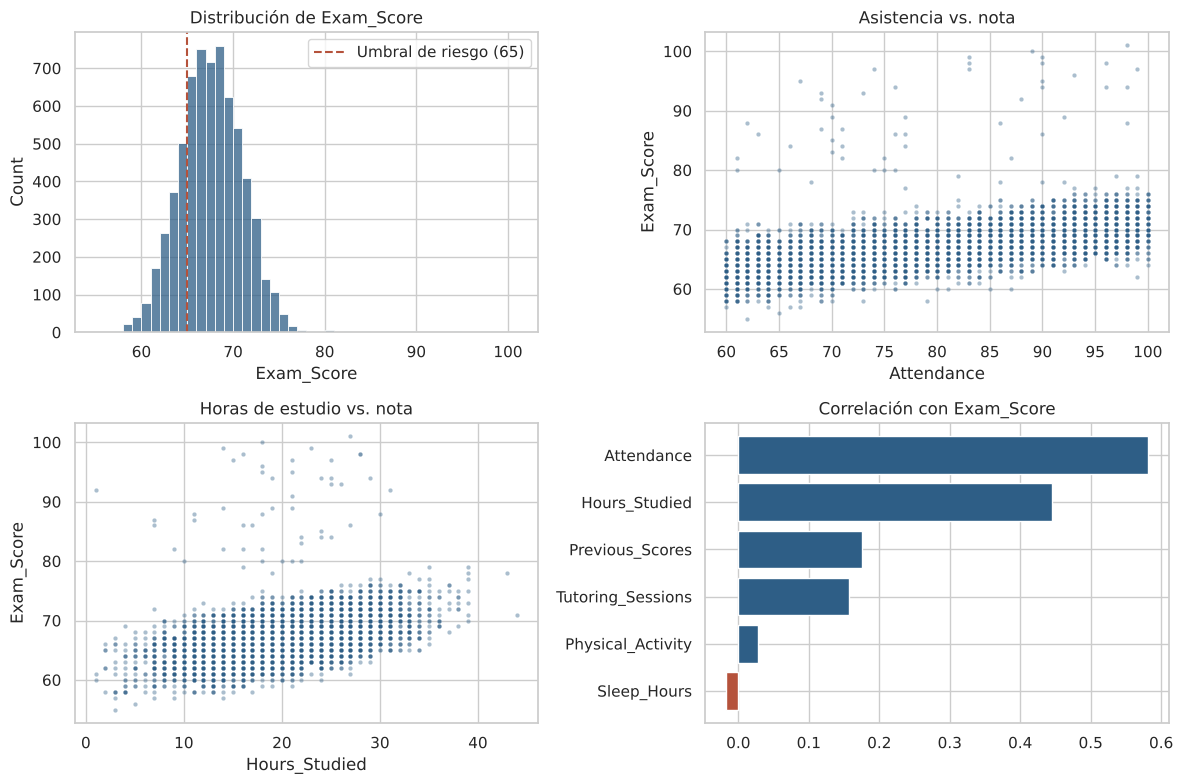

In [4]:
y_all = df_raw["Exam_Score"]
print(f"nota promedio: {y_all.mean():.2f}  desviación: {y_all.std():.2f}")
print(f"estudiantes con nota < {NOTA_RIESGO}: {(y_all < NOTA_RIESGO).mean():.1%}")
print("notas de 80 o más:", (y_all >= 80).sum())

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
sns.histplot(y_all, bins=46, ax=axes[0, 0], color=AZUL)
axes[0, 0].axvline(NOTA_RIESGO, color=ROJO, ls="--", label="Umbral de riesgo (65)")
axes[0, 0].set_title("Distribución de Exam_Score"); axes[0, 0].legend()

sns.scatterplot(data=df_raw, x="Attendance", y="Exam_Score", ax=axes[0, 1], s=10, alpha=0.4, color=AZUL)
axes[0, 1].set_title("Asistencia vs. nota")
sns.scatterplot(data=df_raw, x="Hours_Studied", y="Exam_Score", ax=axes[1, 0], s=10, alpha=0.4, color=AZUL)
axes[1, 0].set_title("Horas de estudio vs. nota")

corr = df_raw.select_dtypes("number").corr()["Exam_Score"].drop("Exam_Score").sort_values()
axes[1, 1].barh(corr.index, corr.values, color=[ROJO if v < 0 else AZUL for v in corr.values])
axes[1, 1].set_title("Correlación con Exam_Score")
guardar("01_eda")

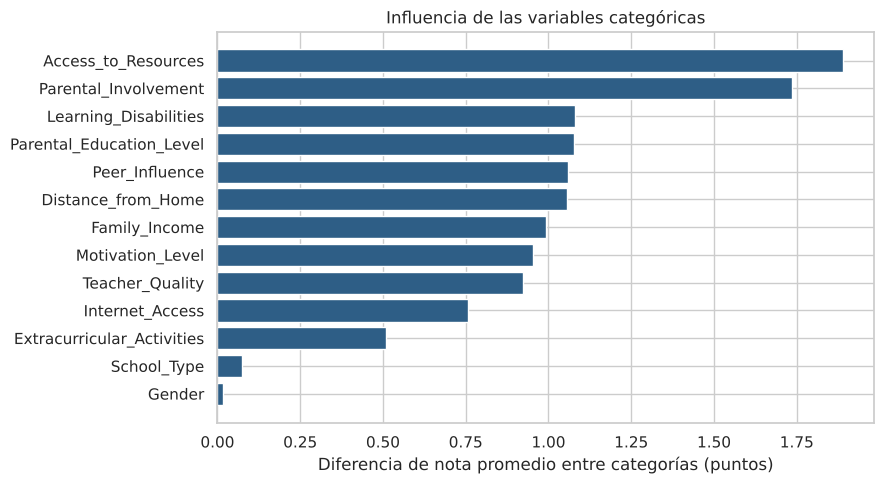

Gender                        0.02
School_Type                   0.07
Extracurricular_Activities    0.51
Internet_Access               0.76
Teacher_Quality               0.92
Motivation_Level              0.95
Family_Income                 0.99
Distance_from_Home            1.05
Peer_Influence                1.06
Parental_Education_Level      1.08
Learning_Disabilities         1.08
Parental_Involvement          1.73
Access_to_Resources           1.89
dtype: float64

In [5]:
# efecto de las variables categóricas: diferencia entre la mejor y la peor categoría
cats = df_raw.select_dtypes(exclude="number").columns
efecto = {c: df_raw.groupby(c)["Exam_Score"].mean() for c in cats}
rango = pd.Series({c: v.max() - v.min() for c, v in efecto.items()}).sort_values()

plt.figure(figsize=(9, 5))
plt.barh(rango.index, rango.values, color=AZUL)
plt.xlabel("Diferencia de nota promedio entre categorías (puntos)")
plt.title("Influencia de las variables categóricas")
guardar("02_categoricas")
rango.round(2)

In [6]:
# modelo base: predecir siempre el promedio
mae_base = mean_absolute_error(y_all, np.full(len(y_all), y_all.mean()))
print(f"MAE del modelo base: {mae_base:.3f} puntos")

# riesgos de sesgo
for c in ["Gender", "Family_Income", "School_Type"]:
    print(df_raw.groupby(c)["Exam_Score"].agg(["count", "mean"]).round(2), "\n")

MAE del modelo base: 2.849 puntos
        count   mean
Gender              
Female   2793  67.24
Male     3814  67.23 

               count   mean
Family_Income              
High            1269  67.84
Low             2672  66.85
Medium          2666  67.33 

             count   mean
School_Type              
Private       2009  67.29
Public        4598  67.21 



## Fase 2: Data Engineering

In [7]:
df = df_raw.copy()
# una nota de 101 no es posible: es un error de registro y se elimina
df = df[df["Exam_Score"] <= 100].reset_index(drop=True)
print(df.shape)

# Gender no entra al modelo: no cambia la nota y solo se usa para revisar equidad
X = df.drop(columns=["Exam_Score", "Gender"])
y = df["Exam_Score"]
genero = df["Gender"]

NUM = ["Hours_Studied", "Attendance", "Sleep_Hours", "Previous_Scores", "Tutoring_Sessions", "Physical_Activity"]
# categorías con orden natural: se codifican como 0, 1, 2 respetando ese orden
ORD = {
    "Parental_Involvement": ["Low", "Medium", "High"],
    "Access_to_Resources": ["Low", "Medium", "High"],
    "Motivation_Level": ["Low", "Medium", "High"],
    "Family_Income": ["Low", "Medium", "High"],
    "Teacher_Quality": ["Low", "Medium", "High"],
    "Peer_Influence": ["Negative", "Neutral", "Positive"],
    "Parental_Education_Level": ["High School", "College", "Postgraduate"],
    "Distance_from_Home": ["Near", "Moderate", "Far"],
}
BIN = ["Extracurricular_Activities", "Internet_Access", "School_Type", "Learning_Disabilities"]

(6606, 20)


In [8]:
# separo test antes de transformar nada, manteniendo la misma proporción de estudiantes en riesgo
X_train, X_test, y_train, y_test, g_train, g_test = train_test_split(
    X, y, genero, test_size=0.20, random_state=SEED, stratify=(y < NOTA_RIESGO))
print("train:", X_train.shape, f"riesgo={np.mean(y_train < NOTA_RIESGO):.3f}")
print("test :", X_test.shape, f"riesgo={np.mean(y_test < NOTA_RIESGO):.3f}")

def construir_prep():
    return ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("esc", StandardScaler())]), NUM),
        ("ord", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                          ("enc", OrdinalEncoder(categories=list(ORD.values()),
                                                 handle_unknown="use_encoded_value", unknown_value=np.nan)),
                          ("imp2", SimpleImputer(strategy="most_frequent"))]), list(ORD)),
        ("bin", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                          ("ohe", OneHotEncoder(drop="if_binary", handle_unknown="ignore"))]), BIN),
    ])

def construir_pipeline(modelo):
    return Pipeline([("prep", construir_prep()), ("modelo", modelo)])

train: (5284, 18) riesgo=0.220
test : (1322, 18) riesgo=0.220


In [9]:
# versionado de los datos
def hash_df(d):
    return hashlib.sha256(pd.util.hash_pandas_object(d, index=True).values.tobytes()).hexdigest()

train_v = X_train.assign(Gender=g_train, Exam_Score=y_train)
test_v = X_test.assign(Gender=g_test, Exam_Score=y_test)
train_v.to_csv("artefactos/datos/train_v1.csv", index=False)
test_v.to_csv("artefactos/datos/test_v1.csv", index=False)

manifiesto = {
    "version": "v1",
    "fecha": datetime.now().isoformat(timespec="seconds"),
    "fuente": "Kaggle lainguyn123/student-performance-factors",
    "sha256_fuente": hashlib.sha256(open(DATA, "rb").read()).hexdigest(),
    "sha256_train": hash_df(train_v), "sha256_test": hash_df(test_v),
    "filas_train": len(train_v), "filas_test": len(test_v), "seed": SEED,
    "cambios": ["se elimina 1 fila con Exam_Score = 101", "Gender fuera del modelo",
                "imputación por moda dentro del pipeline", "codificación ordinal"],
}
json.dump(manifiesto, open("artefactos/datos/manifiesto_v1.json", "w"), indent=2, ensure_ascii=False)
manifiesto

{'version': 'v1',
 'fecha': '2026-11-19T03:19:26',
 'fuente': 'Kaggle lainguyn123/student-performance-factors',
 'sha256_fuente': 'e8df8c4148ef83fb295ca1c092f2c6ee15272c0a8e3018b769a788ab50e96e97',
 'sha256_train': '017b8f663de835a5120a98f897287932deccc8cde964d1f38eb3e4d6ba68fd41',
 'sha256_test': '5e987ee408d12e0e303e7171458d4a0c97fa2c67e7c1ad8cd6c60699c4908284',
 'filas_train': 5284,
 'filas_test': 1322,
 'seed': 42,
 'cambios': ['se elimina 1 fila con Exam_Score = 101',
  'Gender fuera del modelo',
  'imputación por moda dentro del pipeline',
  'codificación ordinal']}

In [10]:
# contrato de entrada para la API: campos, tipos y valores permitidos
contrato = {"campos": {}}
for c in NUM:
    contrato["campos"][c] = {"tipo": "int",
                             "min_entrenamiento": int(X_train[c].min()), "max_entrenamiento": int(X_train[c].max())}
for c, valores in ORD.items():
    contrato["campos"][c] = {"tipo": "str", "valores": valores}
for c in BIN:
    contrato["campos"][c] = {"tipo": "str", "valores": sorted(X_train[c].dropna().unique().tolist())}
contrato["salida"] = {"nota_estimada": "float (0-100)", "riesgo": f"bool (nota_estimada < {NOTA_RIESGO})"}
json.dump(contrato, open("artefactos/api/contrato_api.json", "w"), indent=2, ensure_ascii=False)
print(len(contrato["campos"]), "campos de entrada")

18 campos de entrada


## Fase 3: ML Model Engineering

In [11]:
cv = KFold(n_splits=5, shuffle=True, random_state=SEED)
scoring = {"mae": "neg_mean_absolute_error", "rmse": "neg_root_mean_squared_error", "r2": "r2"}

modelos = {
    "Base (promedio)": DummyRegressor(),
    "Regresión Lineal": LinearRegression(),
    "Regresión Lineal + interacciones": Pipeline([("poly", PolynomialFeatures(2, interaction_only=True, include_bias=False)),
                                                  ("lr", LinearRegression())]),
    "Huber (lineal robusta)": HuberRegressor(max_iter=2000),
    "Árbol de Decisión": DecisionTreeRegressor(max_depth=8, random_state=SEED),
    "Random Forest": RandomForestRegressor(n_estimators=300, n_jobs=-1, random_state=SEED),
    "Hist Gradient Boosting": HistGradientBoostingRegressor(random_state=SEED),
}

filas = []
for nombre, m in modelos.items():
    r = cross_validate(construir_pipeline(m), X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    filas.append({"modelo": nombre, "MAE": -r["test_mae"].mean(), "MAE_std": r["test_mae"].std(),
                  "RMSE": -r["test_rmse"].mean(), "R2": r["test_r2"].mean()})
comparacion = pd.DataFrame(filas).sort_values("MAE")
comparacion.round(3)

,modelo,MAE,MAE_std,RMSE,R2
3,Huber (lineal robusta),0.456,0.036,2.101,0.708
1,Regresión Lineal,0.501,0.033,2.097,0.710
2,Regresión Lineal + interacciones,0.649,0.032,2.147,0.696
6,Hist Gradient Boosting,0.875,0.016,2.246,0.667
5,Random Forest,1.137,0.019,2.416,0.616
4,Árbol de Decisión,1.735,0.054,3.335,0.269
0,Base (promedio),2.852,0.056,3.904,-0.001


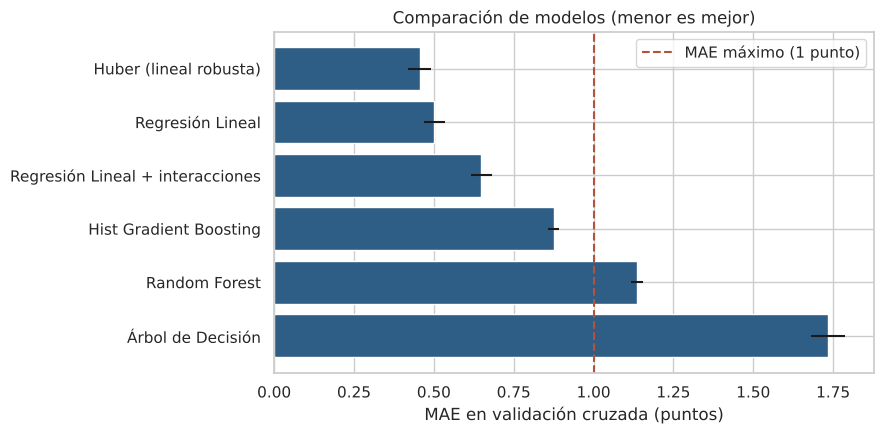

In [12]:
plot = comparacion[comparacion["modelo"] != "Base (promedio)"].sort_values("MAE", ascending=False)
plt.figure(figsize=(9, 4.5))
plt.barh(plot["modelo"], plot["MAE"], xerr=plot["MAE_std"], color=AZUL)
plt.axvline(REQ["mae_max"], color=ROJO, ls="--", label="MAE máximo (1 punto)")
plt.xlabel("MAE en validación cruzada (puntos)"); plt.legend()
plt.title("Comparación de modelos (menor es mejor)")
guardar("03_comparacion")

In [13]:
# los modelos lineales ganan: la nota depende casi en forma aditiva de las variables.
# reviso los errores grandes de la regresión lineal
oof_lr = cross_val_predict(construir_pipeline(LinearRegression()), X_train, y_train, cv=cv)
res = y_train - oof_lr
print("errores mayores a 3 puntos:", (res.abs() > 3).sum(), "de", len(res))
print("notas reales de esos casos:", y_train[res.abs() > 3].min(), "a", y_train[res.abs() > 3].max())
print("% de errores menores a 1 punto:", f"{(res.abs() < 1).mean():.1%}")

errores mayores a 3 puntos: 42 de 5284
notas reales de esos casos: 78 a 100
% de errores menores a 1 punto: 98.4%


In [14]:
# hay unas pocas notas muy altas (78 a 100) que ninguna variable explica.
# Huber reduce el peso de esos casos atípicos, por eso se optimizan Huber y Ridge
grid_huber = GridSearchCV(
    construir_pipeline(HuberRegressor(max_iter=2000)),
    {"modelo__epsilon": [1.1, 1.35, 1.5, 2.0, 3.0], "modelo__alpha": [0.001, 0.01, 0.1, 1.0, 3.0, 10.0]},
    scoring="neg_mean_absolute_error", cv=cv, n_jobs=-1).fit(X_train, y_train)

grid_ridge = GridSearchCV(
    construir_pipeline(Ridge()), {"modelo__alpha": [0.01, 0.1, 1, 10, 100]},
    scoring="neg_mean_absolute_error", cv=cv, n_jobs=-1).fit(X_train, y_train)

# para comparar, también se ajusta el mejor modelo de árboles
rand_hgb = RandomizedSearchCV(
    construir_pipeline(HistGradientBoostingRegressor(random_state=SEED)),
    {"modelo__learning_rate": stats.loguniform(0.01, 0.3), "modelo__max_depth": [2, 3, 4, None],
     "modelo__max_iter": stats.randint(100, 800), "modelo__min_samples_leaf": stats.randint(10, 80)},
    n_iter=30, scoring="neg_mean_absolute_error", cv=cv, n_jobs=-1, random_state=SEED).fit(X_train, y_train)

busquedas = {"Huber": grid_huber, "Ridge": grid_ridge, "Hist Gradient Boosting": rand_hgb}
for n, b in busquedas.items():
    print(f"{n:24s} MAE={-b.best_score_:.4f}  {b.best_params_}")

NOMBRE = min(busquedas, key=lambda k: -busquedas[k].best_score_)
modelo = busquedas[NOMBRE].best_estimator_
print("\nelegido:", NOMBRE)

Huber                    MAE=0.4556  {'modelo__alpha': 3.0, 'modelo__epsilon': 2.0}
Ridge                    MAE=0.5007  {'modelo__alpha': 0.01}
Hist Gradient Boosting   MAE=0.6726  {'modelo__learning_rate': np.float64(0.048917628051312216), 'modelo__max_depth': 2, 'modelo__max_iter': 746, 'modelo__min_samples_leaf': 30}

elegido: Huber


In [15]:
joblib.dump(modelo, "artefactos/modelos/modelo_v1.joblib")
metadatos = {
    "version": "v1", "algoritmo": NOMBRE,
    "parametros": {k: float(v) for k, v in busquedas[NOMBRE].best_params_.items()},
    "mae_cv": round(float(-busquedas[NOMBRE].best_score_), 4),
    "nota_riesgo": NOTA_RIESGO, "seed": SEED,
    "datos": manifiesto["sha256_train"], "sklearn": sklearn.__version__,
    "variables": list(X.columns),
    "fecha": datetime.now().isoformat(timespec="seconds"),
}
json.dump(metadatos, open("artefactos/modelos/metadatos_v1.json", "w"), indent=2, ensure_ascii=False)
metadatos

{'version': 'v1',
 'algoritmo': 'Huber',
 'parametros': {'modelo__alpha': 3.0, 'modelo__epsilon': 2.0},
 'mae_cv': 0.4556,
 'nota_riesgo': 65,
 'seed': 42,
 'datos': '017b8f663de835a5120a98f897287932deccc8cde964d1f38eb3e4d6ba68fd41',
 'sklearn': '1.9.1',
 'variables': ['Hours_Studied',
  'Attendance',
  'Parental_Involvement',
  'Access_to_Resources',
  'Extracurricular_Activities',
  'Sleep_Hours',
  'Previous_Scores',
  'Motivation_Level',
  'Internet_Access',
  'Tutoring_Sessions',
  'Family_Income',
  'Teacher_Quality',
  'School_Type',
  'Peer_Influence',
  'Physical_Activity',
  'Learning_Disabilities',
  'Parental_Education_Level',
  'Distance_from_Home'],
 'fecha': '2026-11-19T03:20:16'}

## Fase 4: ML Model Evaluation & QA

In [16]:
def recall_precision_riesgo(y_real, y_pred):
    real, marcado = y_real < NOTA_RIESGO, y_pred < NOTA_RIESGO
    tp = (real & marcado).sum()
    return tp / real.sum(), tp / marcado.sum()

pred = np.clip(modelo.predict(X_test), 0, 100)
pred_base = np.full(len(y_test), y_train.mean())

mae = mean_absolute_error(y_test, pred)
mae_b = mean_absolute_error(y_test, pred_base)
rmse = mean_squared_error(y_test, pred) ** 0.5
r2 = r2_score(y_test, pred)
rec, prec = recall_precision_riesgo(y_test.values, pred)

resultados = pd.DataFrame([
    {"modelo": NOMBRE, "MAE": mae, "RMSE": rmse, "R2": r2, "recall_riesgo": rec, "precision_riesgo": prec},
    {"modelo": "Base (promedio)", "MAE": mae_b, "RMSE": mean_squared_error(y_test, pred_base) ** 0.5,
     "R2": r2_score(y_test, pred_base), "recall_riesgo": 0.0, "precision_riesgo": np.nan},
])

checks = {
    "MAE <= 1 punto": mae <= REQ["mae_max"],
    "MAE al menos 50% menor que el base": 1 - mae / mae_b >= REQ["mejora_vs_base_min"],
    "R2 >= 0.70": r2 >= REQ["r2_min"],
    "recall de riesgo >= 0.90": rec >= REQ["recall_riesgo_min"],
    "precisión de riesgo >= 0.70": prec >= REQ["precision_riesgo_min"],
}
for k, v in checks.items():
    print("cumple" if v else "NO cumple", "-", k)
print(f"\nmejora frente al modelo base: {1 - mae / mae_b:.1%}")
marcados = pred < NOTA_RIESGO
print(f"en riesgo real: {(y_test < NOTA_RIESGO).sum()}  marcados: {marcados.sum()}  "
      f"bien marcados: {(marcados & (y_test.values < NOTA_RIESGO)).sum()}")
resultados.round(3)

cumple - MAE <= 1 punto
cumple - MAE al menos 50% menor que el base
cumple - R2 >= 0.70
cumple - recall de riesgo >= 0.90
cumple - precisión de riesgo >= 0.70

mejora frente al modelo base: 86.6%
en riesgo real: 291  marcados: 359  bien marcados: 291


,modelo,MAE,RMSE,R2,recall_riesgo,precision_riesgo
0,Huber,0.376,1.582,0.819,1.0,0.811
1,Base (promedio),2.810,3.722,-0.000,0.0,NaN


errores menores a 1 punto: 99.4%
errores menores a 2 puntos: 99.5%
estudiantes en riesgo con nota sobreestimada en más de 1 punto: 0 de 291


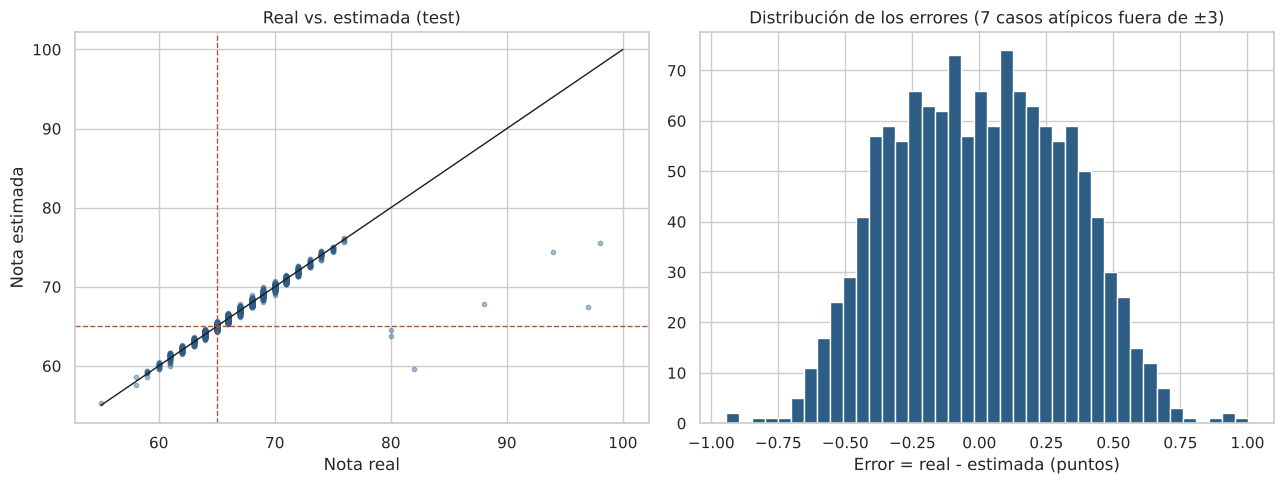

In [17]:
err = y_test.values - pred
print(f"errores menores a 1 punto: {(np.abs(err) < 1).mean():.1%}")
print(f"errores menores a 2 puntos: {(np.abs(err) < 2).mean():.1%}")
riesgo = y_test.values < NOTA_RIESGO
print(f"estudiantes en riesgo con nota sobreestimada en más de 1 punto: {(err[riesgo] < -1).sum()} de {riesgo.sum()}")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(y_test, pred, s=10, alpha=0.4, color=AZUL)
axes[0].plot([55, 100], [55, 100], color="k", lw=1)
axes[0].axvline(NOTA_RIESGO, color=ROJO, ls="--", lw=1); axes[0].axhline(NOTA_RIESGO, color=ROJO, ls="--", lw=1)
axes[0].set_xlabel("Nota real"); axes[0].set_ylabel("Nota estimada"); axes[0].set_title("Real vs. estimada (test)")
axes[1].hist(err[np.abs(err) <= 3], bins=40, color=AZUL)
axes[1].set_xlabel("Error = real - estimada (puntos)")
axes[1].set_title(f"Distribución de los errores ({(np.abs(err) > 3).sum()} casos atípicos fuera de ±3)")
guardar("04_test")

In [18]:
# robustez: ruido en las numéricas y cambios aleatorios de categoría
def perturbar(X, nivel, rng):
    Xp = X.copy()
    for c in NUM:
        Xp[c] = np.clip(X[c] + rng.normal(0, nivel * X[c].std(), len(X)), X[c].min(), X[c].max()).round()
    for c in list(ORD) + BIN:
        m = rng.random(len(X)) < nivel / 2
        Xp.loc[m, c] = rng.choice(X[c].dropna().unique(), m.sum())
    return Xp

rng = np.random.default_rng(SEED)
robustez = []
for nivel in [0, 0.05, 0.10, 0.20, 0.30]:
    maes, recs = [], []
    for _ in range(5):
        p = np.clip(modelo.predict(perturbar(X_test, nivel, rng)), 0, 100)
        maes.append(mean_absolute_error(y_test, p)); recs.append(recall_precision_riesgo(y_test.values, p)[0])
    robustez.append({"ruido": nivel, "MAE": np.mean(maes), "recall_riesgo": np.mean(recs)})
pd.DataFrame(robustez).round(3)

,ruido,MAE,recall_riesgo
0,0.00,0.376,1.000
1,0.05,0.493,0.988
2,0.10,0.615,0.977
3,0.20,0.887,0.947
4,0.30,1.111,0.908


In [19]:
# explicabilidad: como el modelo es lineal, cada coeficiente es el efecto de la variable
prep = modelo.named_steps["prep"]
nombres = [n.split("__", 1)[1] for n in prep.get_feature_names_out()]
coef = pd.Series(modelo.named_steps["modelo"].coef_, index=nombres)
# las numéricas están estandarizadas: divido por la desviación para tener el efecto por unidad
esc = prep.named_transformers_["num"].named_steps["esc"]
por_unidad = coef.copy()
por_unidad[NUM] = coef[NUM] / esc.scale_
print("efecto por unidad (puntos de nota):")
print(por_unidad.round(3).sort_values(ascending=False).to_string())

efecto por unidad (puntos de nota):
Internet_Access_Yes               1.000
Access_to_Resources               0.998
Parental_Involvement              0.991
Motivation_Level                  0.510
Parental_Education_Level          0.504
Extracurricular_Activities_Yes    0.504
Teacher_Quality                   0.504
Tutoring_Sessions                 0.502
Peer_Influence                    0.496
Family_Income                     0.495
Hours_Studied                     0.298
Physical_Activity                 0.233
Attendance                        0.200
Previous_Scores                   0.049
Sleep_Hours                       0.019
School_Type_Public                0.006
Distance_from_Home               -0.496
Learning_Disabilities_Yes        -0.987


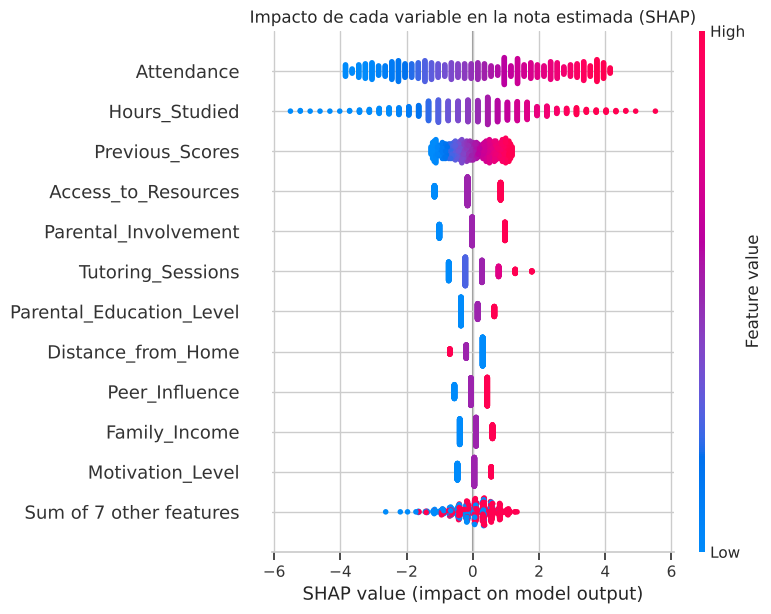

In [20]:
Xtr_t = pd.DataFrame(prep.transform(X_train), columns=nombres)
Xte_t = pd.DataFrame(prep.transform(X_test), columns=nombres)
explainer = shap.LinearExplainer(modelo.named_steps["modelo"], shap.sample(Xtr_t, 100, random_state=SEED))
sv = explainer(Xte_t.sample(600, random_state=SEED))
shap.plots.beeswarm(sv, max_display=12, show=False)
plt.title("Impacto de cada variable en la nota estimada (SHAP)")
guardar("05_shap")

In [21]:
# equidad: el error y el sesgo deberían ser parecidos entre grupos
filas = []
grupos = {"Gender": g_test.values, "Family_Income": X_test["Family_Income"].values, "School_Type": X_test["School_Type"].values}
for atr, valores in grupos.items():
    for g in pd.Series(valores).dropna().unique():
        m = valores == g
        r, _ = recall_precision_riesgo(y_test.values[m], pred[m])
        normal = m & (np.abs(err) <= 3)   # sin las notas atípicas que ningún modelo explica
        filas.append({"atributo": atr, "grupo": g, "n": m.sum(), "MAE": mean_absolute_error(y_test.values[m], pred[m]),
                      "MAE_sin_atipicos": mean_absolute_error(y_test.values[normal], pred[normal]),
                      "atipicos": int((m & (np.abs(err) > 3)).sum()),
                      "sesgo_medio": (pred[m] - y_test.values[m]).mean(), "recall_riesgo": r})
equidad = pd.DataFrame(filas)
equidad.round(3)

,atributo,grupo,n,MAE,MAE_sin_atipicos,atipicos,sesgo_medio,recall_riesgo
0,Gender,Female,579,0.267,0.267,0,-0.016,1.0
1,Gender,Male,743,0.462,0.268,7,-0.191,1.0
2,Family_Income,Medium,555,0.265,0.265,0,-0.016,1.0
3,Family_Income,High,250,0.514,0.259,3,-0.247,1.0
4,Family_Income,Low,517,0.430,0.275,4,-0.157,1.0
5,School_Type,Public,921,0.375,0.265,5,-0.112,1.0
6,School_Type,Private,401,0.379,0.274,2,-0.121,1.0


In [22]:
model_card = f"""# Model Card - modelo_v1

Modelo: {NOMBRE} (scikit-learn {sklearn.__version__}), parámetros {metadatos['parametros']}
Uso previsto: estimar la nota del examen para ofrecer tutoría a quien tenga nota estimada < {NOTA_RIESGO}.
No usar para: calificar, sancionar ni excluir estudiantes; las decisiones las toma el docente.
Datos: Student Performance Factors (Kaggle), {len(X_train)} estudiantes en train y {len(X_test)} en test.
Variables: {len(X.columns)} (Gender excluido y usado solo para auditar equidad).

Resultados en test:
- MAE = {mae:.3f} puntos (modelo base: {mae_b:.3f}), RMSE = {rmse:.3f}, R2 = {r2:.3f}
- Recall de riesgo = {rec:.3f}, precisión de riesgo = {prec:.3f}

Limitaciones:
- Un pequeño grupo de notas muy altas (78-100) no se explica con las variables y el modelo las subestima.
- Fuera de los rangos de entrenamiento (por ejemplo asistencia < 60 %) el modelo extrapola.
- Datos de un solo periodo; hay que monitorear drift en producción.
"""
open("artefactos/modelos/MODEL_CARD.md", "w", encoding="utf-8").write(model_card)
print(model_card)

# Model Card - modelo_v1

Modelo: Huber (scikit-learn 1.9.1), parámetros {'modelo__alpha': 3.0, 'modelo__epsilon': 2.0}
Uso previsto: estimar la nota del examen para ofrecer tutoría a quien tenga nota estimada < 65.
No usar para: calificar, sancionar ni excluir estudiantes; las decisiones las toma el docente.
Datos: Student Performance Factors (Kaggle), 5284 estudiantes en train y 1322 en test.
Variables: 18 (Gender excluido y usado solo para auditar equidad).

Resultados en test:
- MAE = 0.376 puntos (modelo base: 2.810), RMSE = 1.582, R2 = 0.819
- Recall de riesgo = 1.000, precisión de riesgo = 0.811

Limitaciones:
- Un pequeño grupo de notas muy altas (78-100) no se explica con las variables y el modelo las subestima.
- Fuera de los rangos de entrenamiento (por ejemplo asistencia < 60 %) el modelo extrapola.
- Datos de un solo periodo; hay que monitorear drift en producción.



In [23]:
# prueba final: el modelo guardado carga bien y responde a un estudiante nuevo, igual que lo hará la API
modelo_cargado = joblib.load("artefactos/modelos/modelo_v1.joblib")
ejemplo = X_test.iloc[[0]]
nota = float(np.clip(modelo_cargado.predict(ejemplo)[0], 0, 100))
print(ejemplo.T.squeeze().to_dict())
print({"nota_estimada": round(nota, 2), "riesgo": nota < NOTA_RIESGO, "nota_real": int(y_test.iloc[0])})

{'Hours_Studied': 20, 'Attendance': 89, 'Parental_Involvement': 'High', 'Access_to_Resources': 'High', 'Extracurricular_Activities': 'Yes', 'Sleep_Hours': 8, 'Previous_Scores': 52, 'Motivation_Level': 'Low', 'Internet_Access': 'Yes', 'Tutoring_Sessions': 2, 'Family_Income': 'Medium', 'Teacher_Quality': 'Medium', 'School_Type': 'Public', 'Peer_Influence': 'Negative', 'Physical_Activity': 3, 'Learning_Disabilities': 'No', 'Parental_Education_Level': 'College', 'Distance_from_Home': 'Moderate'}
{'nota_estimada': 69.07, 'riesgo': False, 'nota_real': 69}
